# Saltiness peptides: evidence and source-transfer experiment

Independent analysis by Ratchanon Preecha, 15 October 2026.

**Question:** can simple peptide models generalize across literature references, and does the combined salty/saltiness-enhancing label support selecting an enhancer?

This notebook actually refits the fixed baselines on the public 580-record SaltyMeta v1 workbook. It separately evaluates 251 sensory-tagged records, runs reference-disjoint and matched controls, and compares the endpoints in a new October 2026 sensory study. It is **not a reproduction of the released SaltyMeta ESM2 model** and makes no new-compound, receptor-activation or safety claim.

CPU is sufficient. A complete reviewed local fit took around one minute for the main analysis plus additional diagnostics and setup; allow several minutes on a fresh Colab runtime. No GPU, API key, upload or historical archive is needed. All inputs and readable analysis code are embedded. Every Run all reruns the calculations; no hidden result cache.

Sources: [Chen et al., arXiv:2609.16809v1](https://arxiv.org/abs/2609.16809v1); [Kong et al., 2026](https://doi.org/10.1038/s41538-026-01088-9); [Xu et al., 2017](https://doi.org/10.1038/s41598-017-07756-x).

The unchanged SaltyMeta workbook is attributed to Wanchao Chen, Wen Li, Yanan He and Yan Yang. The arXiv source release is CC BY-SA 4.0; that attribution/licence applies to the included source data and its derivatives. Original scientific articles and their full text are not embedded. The analysis code retains the repository's existing academic-review terms.

In [1]:
from pathlib import Path
import os,sys,subprocess,shutil,hashlib,json,base64,io,zipfile,csv,html,time
from IPython.display import display,HTML,Image,FileLink
os.environ['MPLBACKEND']='Agg'
BASE=Path('/content/salt_sensory_validation') if Path('/content').is_dir() else Path.cwd()/'salt_sensory_validation'
WORK=BASE/'work';WORK.mkdir(parents=True,exist_ok=True)
PAYLOAD_SHA256='3f01db80cb7f6a15d05399d9e57ed594fb9fc2db6b5cf29e215b3de0b84bc546'
EMBEDDED_INPUTS='...'
raw=base64.b64decode(EMBEDDED_INPUTS)
assert hashlib.sha256(raw).hexdigest()==PAYLOAD_SHA256
with zipfile.ZipFile(io.BytesIO(raw)) as z:
    for name in z.namelist():
        path=(WORK/name).resolve()
        if not path.is_relative_to(WORK.resolve()):raise ValueError('Unexpected input path')
        path.parent.mkdir(parents=True,exist_ok=True);path.write_bytes(z.read(name))
LOGS=BASE/'logs';LOGS.mkdir(exist_ok=True)
print('Verified embedded input package:',PAYLOAD_SHA256)
print('Readable code and source workbook:',WORK)


Verified embedded input package: 3f01db80cb7f6a15d05399d9e57ed594fb9fc2db6b5cf29e215b3de0b84bc546
Readable code and source workbook: /workspace/scratch/cadb742a5030/research/continuation_20261015/notebook_validation/salt_sensory_validation/work


## Set up the isolated CPU environment

The notebook kernel and scientific worker are separate. Workers use Python 3.12 and pinned binary packages, preserving the earlier backend fix (`MPLBACKEND=Agg`). Setup does not replace the notebook kernel's NumPy or scikit-learn.

In [2]:
def command(args,name,timeout=900):
    env=os.environ.copy();env.update(MPLBACKEND='Agg',OMP_NUM_THREADS='2',OPENBLAS_NUM_THREADS='2')
    path=LOGS/(name+'.log');start=time.monotonic()
    print('Running:',name,flush=True)
    with path.open('w') as out:
        result=subprocess.run([str(a) for a in args],cwd=WORK,env=env,stdout=out,stderr=subprocess.STDOUT,timeout=timeout)
    if result.returncode:
        print(path.read_text(errors='replace')[-5000:]);raise RuntimeError('Failed: '+name+'; log: '+str(path))
    print(name,':',round(time.monotonic()-start,1),'seconds',flush=True)

uv=shutil.which('uv')
if uv is None or subprocess.check_output([uv,'--version'],text=True).split()[1]!='0.12.23':
    bootstrap=BASE/'bootstrap'
    command([sys.executable,'-m','pip','install','--quiet','--upgrade','--only-binary=:all:','--target',bootstrap,'uv==0.12.23'],'bootstrap_uv')
    uv=str(bootstrap/'bin/uv')
PY=BASE/'python312/bin/python'
if not PY.exists():command([uv,'venv','--python','3.12',PY.parent.parent],'create_python312')
command([uv,'pip','install','--python',PY,'--only-binary',':all:','-r',WORK/'requirements_locked.txt'],'install_locked_packages')
command([uv,'pip','check','--python',PY],'check_dependencies')
expected=dict(line.split('==') for line in (WORK/'requirements_locked.txt').read_text().splitlines() if '==' in line and not line.startswith('#'))
query='import sys,json,importlib.metadata as m;print(json.dumps({"python":list(sys.version_info[:3]),"packages":{n:m.version(n) for n in '+repr(list(expected))+'}}))'
actual=json.loads(subprocess.check_output([str(PY),'-c',query],text=True))
assert actual['python'][:2]==[3,12] and actual['packages']==expected
(WORK/'worker_environment.json').write_text(json.dumps(actual,indent=2))
print('Verified Python',actual['python'],'and',len(expected),'locked packages.')


Running: create_python312
create_python312 : 0.1 seconds
Running: install_locked_packages
install_locked_packages : 18.0 seconds
Running: check_dependencies
check_dependencies : 0.0 seconds
Verified Python [3, 12, 14] and 19 locked packages.


## Fit the fixed models

The protocol was written after reading the input schema and evidence counts, before inspecting model predictions. Four fixed baselines; no hyperparameter or embedding search. The designated main model is ExtraTrees with 28 composition/physicochemical features. The 251-record subset contains 138 positive and 113 negative records with the specified curator sensory tags; we have not independently revalidated every source.

Reference groups connect shared DOI-like tokens and similar sequences. This is conservative reference connectivity, not a claim of perfectly reconstructed independent experimental studies. Missing standalone salty taste is not a valid negative for saltiness enhancement.

In [3]:
print((WORK/'PROTOCOL.md').read_text())
command([PY,WORK/'analyse.py'],'main_analysis')
RESULTS=WORK/'results'
def table(name,limit=30):
    with (RESULTS/name).open(newline='') as f:
        reader=csv.DictReader(f);columns=reader.fieldnames;rows=list(reader)
    head=''.join('<th>'+html.escape(c)+'</th>' for c in columns)
    body=''.join('<tr>'+''.join('<td>'+html.escape(str(r[c]))+'</td>' for c in columns)+'</tr>' for r in rows[:limit])
    display(HTML('<div style="overflow:auto"><table><thead><tr>'+head+'</tr></thead><tbody>'+body+'</tbody></table></div>'))
    print(len(rows),'rows; showing',min(limit,len(rows)),'. Full file:',RESULTS/name)
table('metric_summary.csv')
print((RESULTS/'evidence_audit.json').read_text())


# Saltiness evidence continuation — frozen analysis plan

Date: 2026-10-15. This plan is written after inspecting source schemas and evidence counts, before fitting or inspecting predictions.

Question: can simple sequence models generalize across literature sources in the newly obtained SaltyMeta dataset, and does its combined label answer a saltiness-enhancement question?

Inputs: Chen et al., arXiv:2609.16809v1, original Supplementary Data workbook. Retain all 580 labels as supplied. The quantitative CaSR series is a separate endpoint and is not merged with this dataset. Canonical one-letter sequences must not be interpreted as encoding gamma linkages, nonstandard residues, or stereochemical variants.

Analysis cohorts: (1) all 580 entries; (2) 138 positive records tagged Direct sensory evidence and 113 negative records graded A1 or B1. These are curator tags, not our independent confirmation of every source. A2 instrumental negatives and database negatives are excluded from cohort 

cohort,regime,model,auc_mean,auc_min,auc_max,ap_mean,balanced_accuracy_mean
all,random,charge_length,0.5801031746031746,0.567827380952381,0.5902083333333333,0.5794067505935739,0.559484126984127
all,random,composition_logistic,0.6360952380952382,0.6279880952380953,0.6445119047619048,0.597928380712532,0.59
all,random,extra_trees,0.7028015873015873,0.6984761904761905,0.7066190476190476,0.682192997102078,0.6496031746031746
all,random,length_only,0.5159642857142858,0.5016666666666667,0.5259404761904761,0.49186306949908487,0.5333333333333333
all,similarity,charge_length,0.5896746031746032,0.5831309523809524,0.5968333333333333,0.587811840123713,0.5667460317460318
all,similarity,composition_logistic,0.6444702380952382,0.6395952380952381,0.6527559523809524,0.6011919315811475,0.6016666666666667
all,similarity,extra_trees,0.7006051587301587,0.6998869047619048,0.701357142857143,0.6806917433092282,0.6526984126984127
all,similarity,length_only,0.526765873015873,0.5253035714285714,0.5279047619047619,0.5060154401771048,0.5333333333333333
sensory_tagged,random,charge_length,0.5423667222435979,0.5416826984737719,0.5434461972553546,0.6242219034104523,0.5283762985763755
sensory_tagged,random,composition_logistic,0.6728228805951008,0.6539053482108503,0.6912273951519815,0.7093996171584299,0.6220020520713095


## Post-hoc controls and source checks

These diagnostics were added after the below-chance reference-blocked result appeared. They are labelled post-hoc: matched training/test size and class counts, within-fold AUC, and removal of selected secondary or malformed references. They do not change the model selection. Fifteen matched draws are not fifteen independent experimental replications.

The bootstrap is descriptive source-cluster resampling of the fixed OOF predictions, not a retraining confidence interval or proof about the published SaltyMeta model.

# Diagnostics added after the initial results

The initial designated ExtraTrees result fell below chance under reference-and-similarity grouping. Before interpreting this as failure to transfer, perform the following diagnostics. These were specified after observing that result and are not preregistered primary analyses.

1. Report AUC separately within each held-out fold, with test size and class counts, to check whether pooled scores from different fitted models create the entire result.
2. For each original reference-blocked fold, draw a random test sample of the identical size and class counts, with its complement used for training. This controls training size and class proportion, but permits source/similarity overlap. Fix seed 40000 + original seed + fold. Evaluate only the already designated ExtraTrees model; no tuning.
3. Rebuild reference connectivity after removing two visibly truncated DOI tokens, one malformed DOI token, and four verified secondary-review/model references.

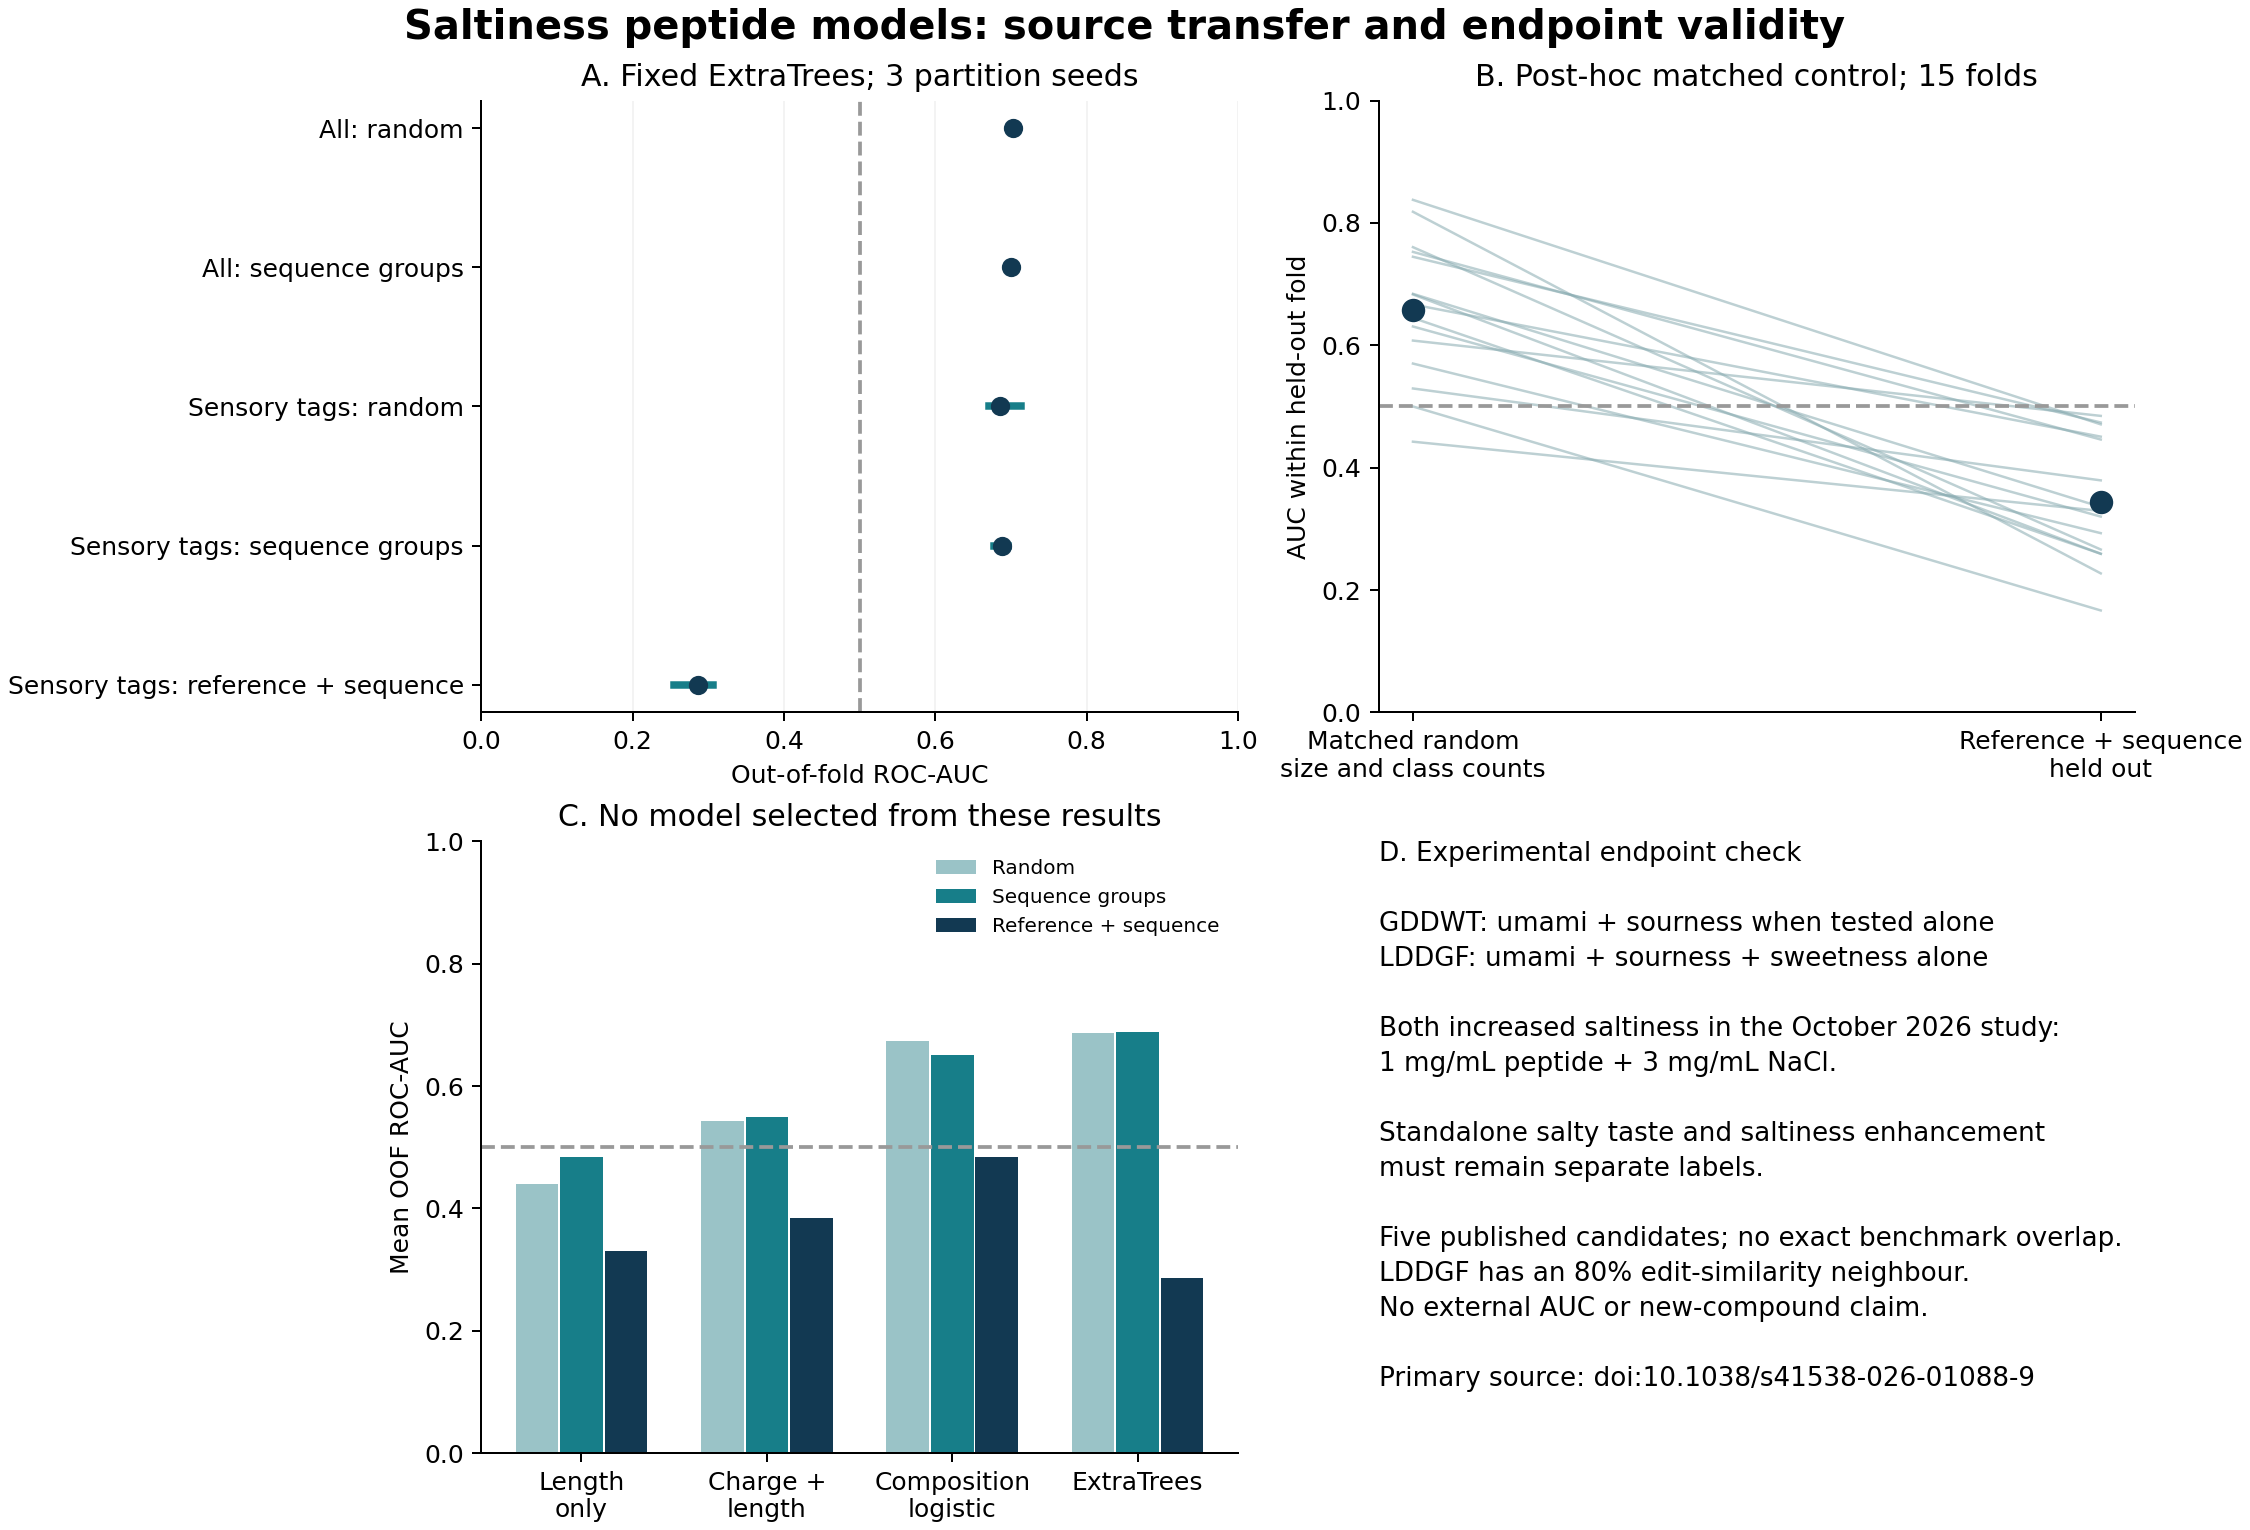

In [4]:
print((WORK/'POSTHOC_DIAGNOSTICS.md').read_text())
command([PY,WORK/'diagnose.py'],'posthoc_diagnostics')
command([PY,WORK/'report.py'],'verify_and_plot')
display(Image(filename=str(RESULTS/'evidence_and_transfer.png')))
print((RESULTS/'posthoc_summary.json').read_text())
print((RESULTS/'verification.json').read_text())


## Primary sensory evidence and model scope

The October 2026 mushroom paper reports five synthesized candidates. Its Table 1 lists no standalone salty descriptor for GDDWT or LDDGF, yet both increased saltiness when added to 3 mg/mL NaCl at 1 mg/mL peptide. The taste thresholds in the table are not saltiness-enhancement EC50 values. Two other candidates are described as having less-pronounced effects; we do not fabricate definite negative labels for them.

No exact sequence occurs in the 580-record benchmark, but LDDGF has an 80% edit-similarity neighbour. A small, author-selected panel is not a clean population-level external accuracy test. Scores below are those of **our fixed baselines**, not the released ESM2 model; entries also present in training are marked. The 2017 cellular controls are a separate mechanistic endpoint and are not independent sensory validation.

In [5]:
table('october_mushroom_evidence.csv')
table('arginyl_cellular_controls.csv')
table('literature_panel_scores.csv',24)
print('Decision: resolve endpoint and primary-source labels before using these scores to select new compounds.')
print('CaSR potency, standalone salty taste, NaCl enhancement and cellular NaCl-response enhancement remain separate measurements.')


5 rows; showing 5 . Full file: /workspace/scratch/cadb742a5030/research/continuation_20261015/notebook_validation/salt_sensory_validation/work/results/october_mushroom_evidence.csv
7 rows; showing 7 . Full file: /workspace/scratch/cadb742a5030/research/continuation_20261015/notebook_validation/salt_sensory_validation/work/results/arginyl_cellular_controls.csv
96 rows; showing 24 . Full file: /workspace/scratch/cadb742a5030/research/continuation_20261015/notebook_validation/salt_sensory_validation/work/results/literature_panel_scores.csv
Decision: resolve endpoint and primary-source labels before using these scores to select new compounds.
CaSR potency, standalone salty taste, NaCl enhancement and cellular NaCl-response enhancement remain separate measurements.


sequence,standalone_descriptors,taste_threshold_mM,NaCl_sensory_enhancement,doi,publication_date,NaCl_mg_mL,peptide_mg_mL,standalone_salty_descriptor_listed,benchmark_exact_match,nearest_benchmark_sequence,edit_similarity
FGDDP,umami; sourness,0.11,effect described as less pronounced; not assigned negative here,10.1038/s41538-026-01088-9,2026-10-02,3,1,False,False,FAGDDAPR,0.625
GDDWT,umami; sourness,0.11,significant increase reported,10.1038/s41538-026-01088-9,2026-10-02,3,1,False,False,GDW,0.6
ASHGEGF,umami; sourness; saltiness,0.13,significant increase reported,10.1038/s41538-026-01088-9,2026-10-02,3,1,True,False,ADHPF,0.4285714285714286
DDPRLP,umami; sourness; bitterness,0.09,effect described as less pronounced; not assigned negative here,10.1038/s41538-026-01088-9,2026-10-02,3,1,False,False,DDL,0.5
LDDGF,umami; sourness; sweetness,0.06,significant increase reported,10.1038/s41538-026-01088-9,2026-10-02,3,1,False,False,LDGF,0.8


sequence,cellular_NaCl_response_increase,doi,combined_benchmark_label,benchmark_references
AR,True,10.1038/s41598-017-07756-x,1,Current_curated; BIOPEP-UWM; 10.1016/j.tifs.2022.11.; jafc.2011.jf2041593
RA,True,10.1038/s41598-017-07756-x,1,Current_curated; BIOPEP-UWM; 10.1016/j.tifs.2022.11.; jafc.2011.jf2041593
RP,True,10.1038/s41598-017-07756-x,1,BIOPEP-UWM; 10.1016/j.tifs.2022.11.
RE,False,10.1038/s41598-017-07756-x,1,TastePeptidesDB; 10.1080/10408398.2025.2547284; 10.1016/j.foodchem.2024.141552
ER,False,10.1038/s41598-017-07756-x,0,10.1016/j.foodres.2024.114966; 10.1038/s41598-017-07756-x
DD,False,10.1038/s41598-017-07756-x,1,Current_curated; TastePeptidesDB; BIOPEP-UWM; 10.1016/j.fufo.2026.100930; 10.1002/fsh3.12055; 10.1016/j.meatsci.2023.109261; 10.1016/j.tifs.2022.11.; 10.1007/s13197--04836-1; 10.1271/bbb.59.; s13197--04836-1; abc.1989.10869317
ED,False,10.1038/s41598-017-07756-x,1,Current_curated; TastePeptidesDB; BIOPEP-UWM; 10.1002/fsh3.12055; 10.1016/j.meatsci.2023.109261; 10.1016/j.tifs.2022.11.; 10.1007/s13197--04836-1; 10.1271/bbb.59.; 10.1016/j.fufo.2026.100930; s13197--04836-1; abc.1989.10869317


cohort,model,sequence,score,in_training
all,length_only,FGDDP,0.4938536457602345,False
all,length_only,GDDWT,0.4938536457602345,False
all,length_only,ASHGEGF,0.5113282285175926,False
all,length_only,DDPRLP,0.5025917285731105,False
all,length_only,LDDGF,0.4938536457602345,False
all,length_only,AR,0.4676832034867584,True
all,length_only,RA,0.4676832034867584,True
all,length_only,RP,0.4676832034867584,True
all,length_only,RE,0.4676832034867584,True
all,length_only,ER,0.4676832034867584,True


## Export the actual run

Includes the input workbook, protocols, executable code, individual predictions, folds, diagnostic controls, figures and logs. Full publisher articles, the Python environment and unrelated historical runs are excluded. Keep the source attribution with redistributed data.

In [6]:
EXPORT=BASE/'Saltiness_Sensory_Run.zip'
with zipfile.ZipFile(EXPORT,'w',zipfile.ZIP_DEFLATED) as z:
    for folder in [WORK,LOGS]:
        for path in sorted(folder.rglob('*')):
            if path.is_file() and '__pycache__' not in path.parts:z.write(path,path.relative_to(BASE))
print('Completed run package:',EXPORT,'bytes:',EXPORT.stat().st_size)
display(FileLink(str(EXPORT)))
try:
    from google.colab import files
except ImportError:
    files=None
if files is not None:print('Download with: files.download(str(EXPORT))')


Completed run package: /workspace/scratch/cadb742a5030/research/continuation_20261015/notebook_validation/salt_sensory_validation/Saltiness_Sensory_Run.zip bytes: 762503


/workspace/scratch/cadb742a5030/research/continuation_20261015/notebook_validation/salt_sensory_validation/Saltiness_Sensory_Run.zip